# 05. Attention Padding Mask 적용 전후 비교

`../05_attention_mask.py`의 A05를 바탕으로 같은 입력과 같은 Attention 층에 Padding Mask를 적용하기 전후를 비교합니다.

확인할 내용:
- 0으로 채운 Padding도 mask가 없으면 key로 사용됩니다.
- `key_padding_mask=True`인 위치는 key에서 제외됩니다.
- Padding query의 출력은 자동으로 0이 되지 않으므로 평균 집계에서 따로 제외합니다.

필요 패키지: `torch`, `pandas`, `matplotlib`. 위에서부터 순서대로 실행하세요.

In [1]:
import torch
from torch import nn
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

torch.set_num_threads(1)
torch.manual_seed(42)

# B=2(샘플), T=5(최대 시점), F=16(특성)
x = torch.randn(2, 5, 16)
lengths = torch.tensor([3, 5])
mask = torch.arange(5).unsqueeze(0) >= lengths.unsqueeze(1)
x[mask] = 0

attention = nn.MultiheadAttention(16, 4, dropout=0, batch_first=True).eval()
print("input shape:", tuple(x.shape))
print("lengths:", lengths.tolist())
print("mask (True = ignored key):")
print(mask)

input shape: (2, 5, 16)
lengths: [3, 5]
mask (True = ignored key):
tensor([[False, False, False,  True,  True],
        [False, False, False, False, False]])


## 1. 같은 입력으로 적용 전후 계산

샘플 0의 실제 길이는 3이므로 key 3·4가 Padding입니다. 샘플 1은 길이가 5라서 차단할 key가 없습니다.

`average_attn_weights=False`를 지정하면 weight는 `[B, heads, query T, key T]` 형태입니다. 기본값 `True`에서는 head를 평균하여 `[B, query T, key T]`가 됩니다.

In [2]:
with torch.inference_mode():
    plain, plain_weights = attention(x, x, x, average_attn_weights=False)
    masked, masked_weights = attention(
        x, x, x,
        key_padding_mask=mask,
        average_attn_weights=False,
    )

print("output shape:", tuple(masked.shape))
print("per-head weight shape:", tuple(masked_weights.shape))
comparison = pd.DataFrame({
    "before": [
        plain_weights[0, :, :, 3:].abs().max().item(),
        plain_weights[0].sum(-1).min().item(),
    ],
    "after": [
        masked_weights[0, :, :, 3:].abs().max().item(),
        masked_weights[0].sum(-1).min().item(),
    ],
}, index=["sample 0: max padding key weight", "sample 0: min row weight sum"])
display(comparison)
print("valid query output max change:", round((plain[0, :3] - masked[0, :3]).abs().max().item(), 6))
print("sample 1 output max change:", round((plain[1] - masked[1]).abs().max().item(), 6))

output shape: (2, 5, 16)
per-head weight shape: (2, 4, 5, 5)


,before,after
sample 0: max padding key weight,0.23473,0.0
sample 0: min row weight sum,1.00000,1.0


valid query output max change: 0.27656
sample 1 output max change: 0.0


## 2. Attention weight 시각화

아래 그림은 **샘플 0의 head 평균 weight**입니다. 행은 query, 열은 key입니다. 점선 오른쪽의 key 3·4가 마스크 적용 후 모두 0이 되는지 확인하세요. 아래쪽 query 3·4의 행은 남아 있습니다.

Padding 입력이 0이어도 softmax에서 그 위치의 확률이 자동으로 0이 되지는 않습니다. 마스크를 적용하면 제외된 key의 가중치는 0이 되고 나머지 key 사이에서 가중치가 다시 정규화됩니다.

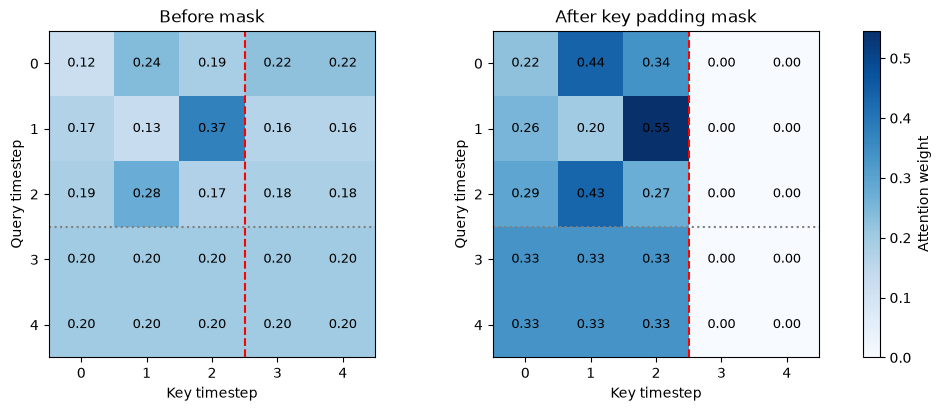

In [3]:
before_map = plain_weights[0].mean(0).numpy()
after_map = masked_weights[0].mean(0).numpy()
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
vmax = max(before_map.max(), after_map.max())
for ax, values, title in zip(axes, [before_map, after_map], ["Before mask", "After key padding mask"]):
    im = ax.imshow(values, vmin=0, vmax=vmax, cmap="Blues")
    ax.set(title=title, xlabel="Key timestep", ylabel="Query timestep")
    ax.set_xticks(range(5))
    ax.set_yticks(range(5))
    ax.axvline(2.5, color="red", linestyle="--")
    ax.axhline(2.5, color="gray", linestyle=":")
    for q in range(5):
        for k in range(5):
            ax.text(k, q, f"{values[q, k]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=axes, label="Attention weight")
plt.show()

## 3. Padding query는 평균에서 별도로 제외

Key mask는 **참조할 key**만 차단합니다. Padding query도 유효한 key를 참조할 수 있어서 출력이 0이라고 보장되지 않습니다.

따라서 시퀀스 대표 벡터는 `masked.mean(1)` 대신 유효 query 출력만 합산하고 실제 길이로 나누어 계산합니다. 비교표의 마지막 두 행은 같은 mask 적용 후 출력에서 평균 방식만 바꾼 결과입니다.

In [4]:
with torch.inference_mode():
    plain_mean = plain.mean(1)
    masked_naive_mean = masked.mean(1)
    valid_mean = (masked * (~mask).unsqueeze(-1)).sum(1) / lengths.unsqueeze(-1)

print("padding query output max abs:", round(masked[0, 3:].abs().max().item(), 6))
print("pooled output shape:", tuple(valid_mean.shape))
display(pd.DataFrame({
    "feature 0": [plain_mean[0, 0].item(), masked_naive_mean[0, 0].item(), valid_mean[0, 0].item()],
    "feature 1": [plain_mean[0, 1].item(), masked_naive_mean[0, 1].item(), valid_mean[0, 1].item()],
}, index=["before: all queries mean", "after: all queries mean", "after: valid queries mean"]))
print("sample 0 pooling max difference:", round((masked_naive_mean[0] - valid_mean[0]).abs().max().item(), 6))

padding query output max abs: 0.535509
pooled output shape: (2, 16)


,feature 0,feature 1
before: all queries mean,-0.022326,0.086490
after: all queries mean,-0.025664,0.122985
after: valid queries mean,-0.001349,0.131846


sample 0 pooling max difference: 0.059471


## 4. 요구사항 자동 확인

차단한 key의 weight가 0이고, 각 query의 weight 합이 1인지 확인합니다. 또한 mask가 없는 샘플은 적용 전후 출력이 같고, 실제 길이로 계산한 평균이 유효 query만 직접 선택한 평균과 같은지 확인합니다.

In [5]:
assert mask.dtype == torch.bool and mask.shape == (2, 5)
assert masked.shape == (2, 5, 16)
assert masked_weights.shape == (2, 4, 5, 5)
assert torch.all(masked_weights[0, :, :, 3:] == 0)
assert torch.allclose(masked_weights.sum(-1), torch.ones(2, 4, 5), atol=1e-6)
assert torch.allclose(plain[1], masked[1], atol=1e-6)
assert torch.allclose(valid_mean[0], masked[0, :3].mean(0), atol=1e-6)
assert torch.allclose(valid_mean[1], masked[1].mean(0), atol=1e-6)
print("All checks passed.")

All checks passed.


## 정리

| 구분 | 적용 전 | 적용 후 |
|---|---|---|
| Padding key weight | 0이 아닐 수 있음 | 0 |
| 유효 query 출력 | Padding key의 영향 포함 | 유효 key만 참조 |
| Padding query 출력 | 0 보장 없음 | 0 보장 없음 |
| 대표 벡터 평균 | Padding query가 섞일 수 있음 | 유효 query만 합산 / 실제 길이 |

**A05 핵심 코드:** `key_padding_mask=mask`. 이 API의 bool mask에서 `True`는 제외할 key입니다. 다른 Attention API에도 같은 의미라고 일반화하지 않습니다.

이 예제는 각 샘플에 유효 key가 하나 이상 있다고 가정합니다. 수치의 마지막 자릿수는 PyTorch 버전과 실행 환경에 따라 달라질 수 있습니다.